In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rc

In [2]:
df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')


In [3]:
rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
rc('text', usetex=True)
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
name = harris_p1['ID']
X = pd.to_numeric(harris_p1['X'],errors='coerce')
Y = pd.to_numeric(harris_p1['Y'],errors='coerce')
Z = pd.to_numeric(harris_p1['Z'],errors='coerce')
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
rho_0 = pd.to_numeric(harris_p3['rho_0'],errors='coerce')
mu_V = pd.to_numeric(harris_p3['mu_V'],errors='coerce')
c = pd.to_numeric(harris_p3['c'],errors='coerce')
BmV = pd.to_numeric(harris_p2['B-V'],errors='coerce')
ellip = pd.to_numeric(harris_p2['ellip'],errors='coerce')
r_c = pd.to_numeric(harris_p3['r_c'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
V_t = pd.to_numeric(harris_p2['V_t'],errors='coerce')
wt = pd.to_numeric(harris_p2['wt'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
v_LSR = pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
mask = mtlc > -0.8

In [4]:
X_gc = X-8
Y_gc = Y
Z_gc = Z

l = L*np.pi/180
b = B*np.pi/180
V0 = 220

In [5]:
v_GSR = v_LSR + V0*np.sin(l)*np.cos(b)

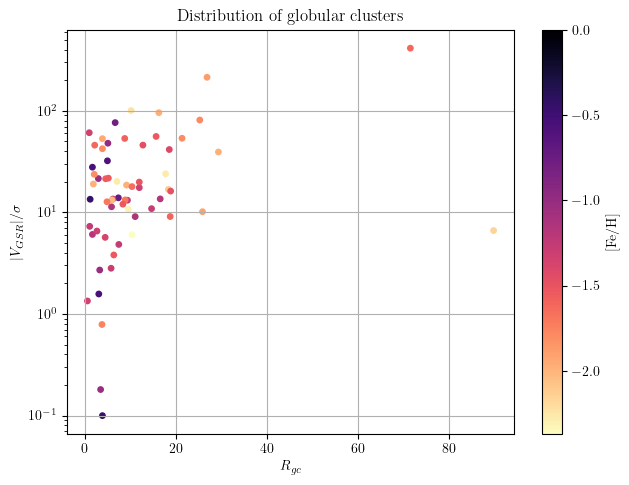

In [ ]:
zmin , zmax = mtlc.min(), mtlc.max()
plt.figure()
plt.scatter(R_gc,abs(v_GSR)/sig_v,15,mtlc,cmap='magma_r',vmin=zmin,vmax=zmax)
plt.colorbar(label =r'$[\mathrm{Fe/H}]$')
plt.xlabel(r'$R_{gc}$')
plt.ylabel(r'$|V_{GSR}|/\sigma$')
# plt.legend()
plt.grid()
# plt.gca().invert_xaxis()
# plt.gca().invert_yaxis()
plt.tight_layout()
plt.xlim()
plt.title(r'Distribution of globular clusters')
plt.yscale('log')
# plt.xscale('log')
plt.show()

In [7]:
mask = ((abs(v_GSR)/sig_v).max() > 200) | (R_gc > 60)
print(np.argmax(((abs(v_GSR)/sig_v))[mask]))
print(name[45])
print(R_gc[45])

45
Pal 14
71.6


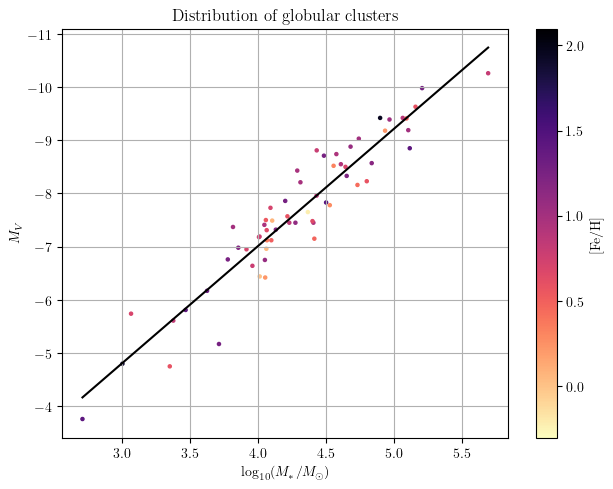

In [ ]:
r_t = 10**c*r_c
G = 4.3009172706*10**(-6) # kpc * (km/s)^2 / M_o
R = r_h*np.pi/(60*180)*R_Sun
M = sig_v**2*R/G
Mlog = np.log10(M)
from scipy.optimize import curve_fit
mask_inf = np.isfinite(Mlog) & np.isfinite(M_V)
x_arr = np.linspace(Mlog.min(),Mlog.max(),100)
def f(x,A,B):
    return A*x+B
param,cov = curve_fit(f,Mlog[mask_inf],M_V[mask_inf])





zmin , zmax = np.log10(R_gc).min(),np.log10(R_gc).max()
plt.figure()
plt.scatter(Mlog,M_V,5,np.log10(R_gc),cmap='magma_r',vmin=zmin,vmax=zmax)
plt.plot(x_arr,f(x_arr,*param),color='black')
plt.colorbar(label =r'[Fe/H]')
plt.xlabel(r'$\log_{10}(M_*/M_\odot)$')
plt.ylabel(r'$M_V$')
plt.grid()
plt.tight_layout()
plt.gca().invert_yaxis()
# plt.gca().invert_xaxis()
plt.title(r'Distribution of globular clusters')
plt.show()

In [102]:
print(cov)

[[ 0.0093767  -0.04025516]
 [-0.04025516  0.17581191]]


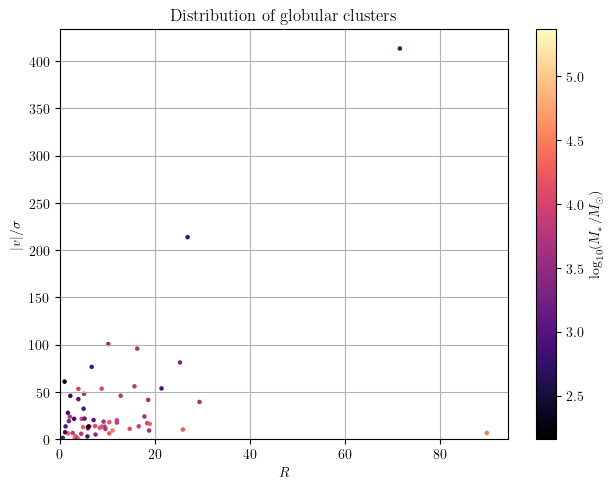

In [ ]:
zmin , zmax = Mlog.min(),Mlog.max()
plt.figure()
plt.scatter(R_gc,abs(v_GSR)/sig_v,5,Mlog,cmap='magma',vmin=zmin,vmax=zmax)
plt.colorbar(label =r'$\log_{10}(M_*/M_\odot)$')
plt.xlabel(r'$R$')
plt.ylabel(r'$|v|/\sigma$')
plt.grid()
plt.tight_layout()
plt.xlim(0)
plt.ylim(0)
plt.title(r'Distribution of globular clusters')
plt.show()